# Install dan Import Library

In [ ]:
!pip install scikit-learn-extra
!pip install numpy==1.26.4

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 819.0/819.0 kB 11.3 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for scikit-learn-extra: filename=scikit_learn_extra-0.3.0-cp312-cp312-linux_x86_64.whl size=2177959 sha256=e4c9e5a8e39632d0f8969febea42cc5018785968cb63b91aa4f5bca7785205fe
  Stored in directory: /root/.cache/pip/wheels/17/4d/c3/c6d5d563c1bf8146d059d63be3678abc2f2801fba0aaf5f0b8
Successfully built scikit-learn-extra
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.0/18.0 MB 88.7 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.0.2
    Uninstalling numpy-2.0.2:
      Successfully uninstalled numpy-2.0.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the f

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.ticker import FuncFormatter
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Load Data

In [ ]:
data = pd.read_excel("Data Clustering.xlsx")
df = pd.DataFrame(data)
df

,Toko,Sales,Membership,Jumlah Transaksi,Pan Storage
0,Bengawan,63290839,20,1072,171.0
1,Blambangan,5939418,0,95,126.0
2,Braga,118514844,45,2141,211.5
3,CCM,75043296,42,1540,162.0
4,Delipark,174114164,52,3602,270.0
5,Marketing,2075354,6,57,126.0
6,Gandaria,22423657,1,308,135.0
7,Margo,57913312,25,1112,171.0
8,SMB,138589786,48,2266,225.0
9,SMB DT,72909267,21,1512,157.5


# Data Preprocessing

In [ ]:
X = df.iloc[:,1:5]
X

,Sales,Membership,Jumlah Transaksi,Pan Storage
0,63290839,20,1072,171.0
1,5939418,0,95,126.0
2,118514844,45,2141,211.5
3,75043296,42,1540,162.0
4,174114164,52,3602,270.0
5,2075354,6,57,126.0
6,22423657,1,308,135.0
7,57913312,25,1112,171.0
8,138589786,48,2266,225.0
9,72909267,21,1512,157.5


In [ ]:
# Pengecekan Missing Value
X.isnull().sum()

,0
Sales,0
Membership,0
Jumlah Transaksi,0
Pan Storage,0


In [ ]:
# Pengecekan Outlier
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)
IQR = Q3 - Q1
outliers = ((X < (Q1 - 1.5 * IQR)) | (X > (Q3 + 1.5 * IQR)))

print("Jumlah Outlier tiap Variabel")
print(outliers.sum())

Jumlah Outlier tiap Variabel
Sales               0
Membership          0
Jumlah Transaksi    0
Pan Storage         0
dtype: int64


In [ ]:
# Pengecekan Indikasi Multikolinearitas
vif = pd.DataFrame()
vif['Variabel'] = X.columns
vif['VIF'] = [variance_inflation_factor(X, i) for i in range(X.shape[1])]

print("Pengujian Asumsi Multikolinearitas")
print(vif)

Pengujian Asumsi Multikolinearitas
           Variabel         VIF
0             Sales  111.400499
1        Membership    7.331707
2  Jumlah Transaksi   82.481100
3       Pan Storage    7.826102


In [ ]:
# Menghapus Variabel yang Terindikasi Multikolinearitas
X = X.drop("Jumlah Transaksi", axis = 1)
X

,Sales,Membership,Pan Storage
0,63290839,20,171.0
1,5939418,0,126.0
2,118514844,45,211.5
3,75043296,42,162.0
4,174114164,52,270.0
5,2075354,6,126.0
6,22423657,1,135.0
7,57913312,25,171.0
8,138589786,48,225.0
9,72909267,21,157.5


In [ ]:
# Scaling / Normalisasi Data
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)
X_scaled


array([[0.34858151, 0.23529412, 0.28571429],
       [0.02200328, 0.        , 0.        ],
       [0.66304552, 0.52941176, 0.54285714],
       [0.41550394, 0.49411765, 0.22857143],
       [0.9796467 , 0.61176471, 0.91428571],
       [0.        , 0.07058824, 0.        ],
       [0.11587006, 0.01176471, 0.05714286],
       [0.31796006, 0.29411765, 0.28571429],
       [0.77735897, 0.56470588, 0.62857143],
       [0.40335206, 0.24705882, 0.2       ],
       [0.19931516, 0.04705882, 0.28571429],
       [0.98077705, 0.63529412, 0.91428571],
       [1.        , 1.        , 1.        ],
       [0.14143224, 0.44705882, 0.05714286],
       [0.23220797, 0.50588235, 0.28571429],
       [0.32338235, 0.82352941, 0.01587302]])

# Statistik Deskriptif

In [ ]:
pd.set_option("display.float_format", lambda x: f"{x:,.2f}".replace(",", "X").replace(".", ",").replace("X", "."))

desc_stats = df.describe().T[['min','max','mean','std']]
print(desc_stats)

                          min            max          mean           std
Sales            2.075.354,00 177.688.471,00 78.032.822,12 60.194.583,58
Membership               0,00          85,00         34,62         25,12
Jumlah Transaksi        57,00       3.782,00      1.448,94      1.190,86
Pan Storage            126,00         283,50        182,12         53,88


# K-Means Clustering

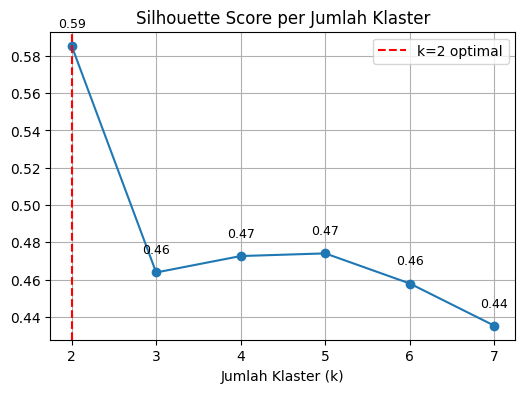

In [ ]:
# Penentuan K Klaster Optimal
sil_scores = []
K_range = range(2, 8)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=22020)
    kmeans.fit(X_scaled)
    labels = kmeans.labels_

    sil_scores.append(silhouette_score(X_scaled, labels))

# Plot Silhoutte Scores
plt.figure(figsize=(6,4))
plt.plot(K_range, sil_scores, marker='o')
for i, score in enumerate(sil_scores):
    plt.text(K_range[i], score+0.01, f"{score:.2f}", ha='center', fontsize=9)
plt.axvline(x=2, color='red', linestyle='--', label="k=2 optimal")
plt.title('Silhouette Score per Jumlah Klaster')
plt.xlabel('Jumlah Klaster (k)')
plt.legend()
plt.grid(True)
plt.show()


Dapat dilihat bahwa nilai Silhoutte Score ketika k = 2 merupakan nilai tertinggi sebesar 0.59, maka toko akan dibagi menjadi 2 klaster.

In [ ]:
# Algoritma K-Means
k_optimal = 2
kmeans = KMeans(n_clusters = k_optimal)
df['Klaster'] = kmeans.fit_predict(X_scaled)
df

,Toko,Sales,Membership,Jumlah Transaksi,Pan Storage,Klaster
0,Bengawan,63290839,20,1072,"171,00",0
1,Blambangan,5939418,0,95,"126,00",0
2,Braga,118514844,45,2141,"211,50",1
3,CCM,75043296,42,1540,"162,00",0
4,Delipark,174114164,52,3602,"270,00",1
5,Marketing,2075354,6,57,"126,00",0
6,Gandaria,22423657,1,308,"135,00",0
7,Margo,57913312,25,1112,"171,00",0
8,SMB,138589786,48,2266,"225,00",1
9,SMB DT,72909267,21,1512,"157,50",0


In [ ]:
# Statistik Deskriptif Kluster 0
num_cols = df.select_dtypes(include=['int64','float64']).columns
desc_cluster_0 = df[df['Klaster'] == 0][num_cols].describe().T[['min','max','mean','std']]
print("Statistik Deskriptif Klaster 0")
print(desc_cluster_0)

Statistik Deskriptif Klaster 0
                          min           max          mean           std
Sales            2.075.354,00 75.043.296,00 42.300.474,55 25.626.918,66
Membership               0,00         70,00         24,55         22,02
Jumlah Transaksi        57,00      1.540,00        766,36        513,09
Pan Storage            126,00        171,00        150,36         20,07


In [ ]:
# Statistik Deskriptif Kluster 1
num_cols = df.select_dtypes(include=['int64','float64']).columns
desc_cluster_1 = df[df['Klaster'] == 1][num_cols].describe().T[['min','max','mean','std']]
print("Statistik Deskriptif Klaster 1")
print(desc_cluster_1)


Statistik Deskriptif Klaster 1
                            min            max           mean           std
Sales            118.514.844,00 177.688.471,00 156.643.986,80 26.646.038,33
Membership                45,00          85,00          56,80         16,15
Jumlah Transaksi       2.141,00       3.782,00       2.950,60        748,30
Pan Storage              211,50         283,50         252,00         31,66


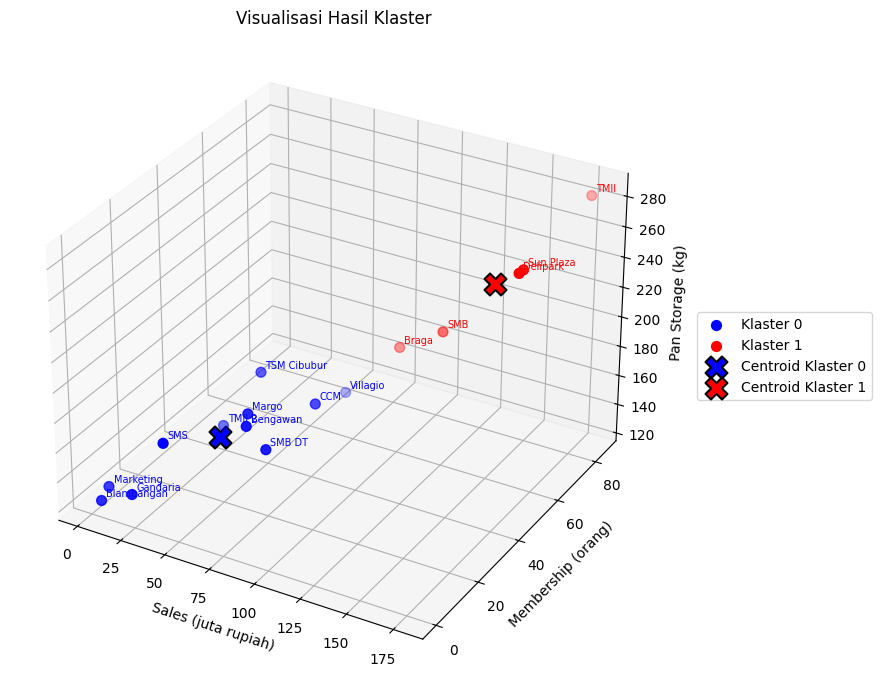

In [ ]:
# Visualisasi Hasil Kluster

cols = X.columns
centers_original = scaler.inverse_transform(kmeans.cluster_centers_)
fig = plt.figure(figsize=(10,7))
ax = fig.add_subplot(111, projection='3d')

colors_map = {0: "blue", 1: "red"}

for cluster_id, color in colors_map.items():
    cluster_points = df[df['Klaster'] == cluster_id]
    ax.scatter(
        cluster_points[cols[0]],
        cluster_points[cols[1]],
        cluster_points[cols[2]],
        c=color, label=f"Klaster {cluster_id}", s=50
    )

    # Label Toko
    for _, row in cluster_points.iterrows():
      ax.text(
          row[cols[0]] + 5,
          row[cols[1]] + 2,
          row[cols[2]],
          row['Toko'],
          fontsize=7, color=color)

# Centroid
for cluster_id, color in colors_map.items():
    ax.scatter(
        centers_original[cluster_id,0],
        centers_original[cluster_id,1],
        centers_original[cluster_id,2],
        c=color, s=250, marker='X', edgecolors='k', linewidths=1.5,
        label=f'Centroid Klaster {cluster_id}'
    )

# Label Sumbu
ax.set_xlabel("Sales (juta rupiah)")
ax.set_ylabel("Membership (orang)")
ax.set_zlabel("Pan Storage (kg)")
ax.set_title("Visualisasi Hasil Klaster")

ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x*1e-6:.0f}'))

# Legend
ax.legend(loc='center left', bbox_to_anchor=(1.05, 0.5))
plt.tight_layout()
plt.show()


In [ ]:
# Persiapan Data untuk Visualisasi Karakteristik Tiap Klaster
df_all = df.copy()
df_all['Klaster'] = 'Keseluruhan'
df_visual = pd.concat([df, df_all], ignore_index=True)
df_visual['Klaster'] = df_visual['Klaster'].astype(str)

order = ['Keseluruhan', '0', '1']
palette = {'Keseluruhan': 'green', '0': 'blue', '1': 'red'}

/tmp/ipython-input-720984658.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


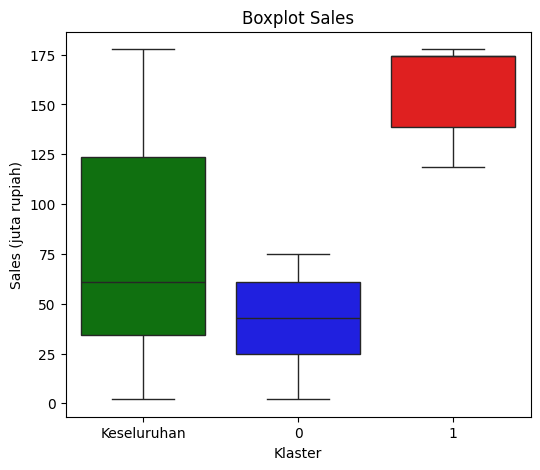

In [ ]:
# Boxplot Sales
plt.figure(figsize=(6,5))
sns.boxplot(
    x='Klaster',
    y=df_visual['Sales'] / 1_000_000,
    data=df_visual,
    order=order,
    palette=palette,
)
plt.title("Boxplot Sales")
plt.ylabel("Sales (juta rupiah)")
plt.show()

/tmp/ipython-input-111750854.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


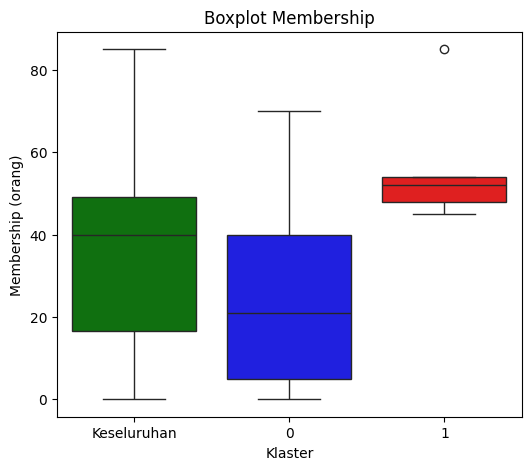

In [ ]:
# Boxplot Membership
plt.figure(figsize=(6,5))
sns.boxplot(
    x='Klaster',
    y=df_visual['Membership'],
    data=df_visual,
    order=order,
    palette=palette,
)
plt.title("Boxplot Membership")
plt.ylabel("Membership (orang)")
plt.show()

/tmp/ipython-input-1502302980.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


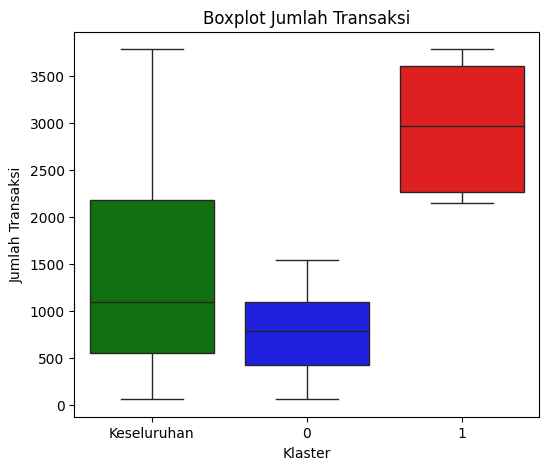

In [ ]:
# Boxplot Jumlah Transaksi
plt.figure(figsize=(6,5))
sns.boxplot(
    x='Klaster',
    y=df_visual['Jumlah Transaksi'],
    data=df_visual,
    order=order,
    palette=palette,
)
plt.title("Boxplot Jumlah Transaksi")
plt.ylabel("Jumlah Transaksi ()")
plt.show()


/tmp/ipython-input-2642058335.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


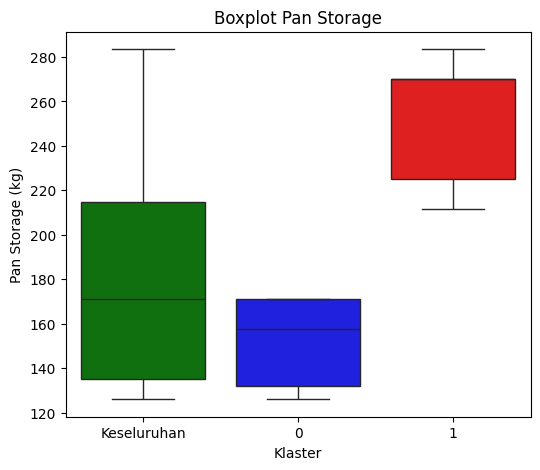

In [ ]:
# Boxplot Pan Storage
plt.figure(figsize=(6,5))
sns.boxplot(
    x='Klaster',
    y=df_visual['Pan Storage'],  # pastikan nama kolom sesuai df kamu
    data=df_visual,
    order=order,
    palette=palette,
)
plt.title("Boxplot Pan Storage")
plt.ylabel("Pan Storage (kg)")
plt.show()
